# COMP0245: golden dataset experiments

This notebook starts from the frozen 300-target dataset and its 200 camera traces. It carries forward the three freshly trained baselines, iterations 34–36, as the starting point for the next experiments. The complete earlier notebook, `driving_v2_sensors.ipynb`, is preserved unchanged.

Re-running this notebook reads and plots saved results. It does not retrain models or run the simulator. Test results below are loaded from saved evaluations. The full data package is on university OneDrive; this repository contains its manifests and a small, explicitly labelled training preview. Use `GOLDEN_DATA_ROOT` for the location of the extracted package when running the training commands in `../arm/GOLDEN_DATA.md`.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
sys.path.insert(0, str(Path('../arm').resolve()))
import report_golden as golden
from report_golden import MODELS, RESULTS
GOLDEN_DATA_ROOT = Path(os.environ['GOLDEN_DATA_ROOT']).expanduser() if os.environ.get('GOLDEN_DATA_ROOT') else None
print('Full dataset:', GOLDEN_DATA_ROOT if GOLDEN_DATA_ROOT else 'not configured; saved manifests, preview and results remain available')
from IPython.display import IFrame, HTML
import uuid

def lazy_player(url, height=810):
    """A 3D player that loads only when its button is pressed. Browsers keep only about 16 3D views (WebGL
    contexts) at once, so loading every player in the notebook together leaves some of them blank."""
    k = uuid.uuid4().hex[:8]
    return HTML(f"""<div><button onclick="var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'"
 style="padding:8px 14px;font-size:14px">Load the 3D player</button>
<iframe id="player{k}" style="display:none;width:100%;height:{height}px;border:0"></iframe></div>""")


Full dataset: not configured; saved manifests, preview and results remain available


## Dataset and split

There are 100 training, 100 validation and 100 reserved test expert runs. Offline camera observations exist for training and validation. Test cameras were rendered live along each learned trajectory in ticket #11110, so expert test camera traces are not needed. Target IDs remain fixed across comparisons.

In [2]:
split = golden.read(MODELS/'dataset_split.json')
manifest = golden.read(MODELS/'dataset_manifest.json')
audit = pd.DataFrame(golden.read(MODELS/'data_audit.json')['rows'])
assert all(len(set(v)) == 100 for v in split.values())
assert len(set().union(*map(set, split.values()))) == 300
display(pd.DataFrame([dict(split=k, expert_runs=len(v), offline_camera_runs=0 if k=='test' else len(v), role={'train':'fit weights and learned scaling','val':'choose epochs and run integration checks','test':'final evaluation only'}[k]) for k,v in split.items()]))
display(audit.groupby('split').agg(runs=('dot','count'),driving_rows=('drive_rows','sum'),arm_rows=('arm_rows','sum'),parked_tail_min=('parked_rows','min'),parked_tail_max=('parked_rows','max')))
print('Frozen split SHA256:', golden.read(MODELS/'data_audit.json')['split_sha256'])

,split,expert_runs,offline_camera_runs,role
0,train,100,100,fit weights and learned scaling
1,val,100,100,choose epochs and run integration checks
2,test,100,0,final evaluation only


,runs,driving_rows,arm_rows,parked_tail_min,parked_tail_max
split,,,,,
train,100,25928,295084,30,100
val,100,26428,288818,13,100


Frozen split SHA256: 286f578aec7e3ab0953592466e63014cc1dde7f467106fadf273b30762ac1abf


## Model inputs and training targets

Driving has 16 inputs: four accumulated encoder angles, four encoder speeds, four combinations of those readings, and camera-tracked range/sin bearing/cos bearing/visibility. Reaching has 17 inputs: seven arm encoder angles, seven encoder speeds and camera-tracked target xyz in the robot frame. Values become FP32 tensors. The camera runs at 30 Hz; its latest estimate is held between arm steps at 1 kHz.

Training targets are the expert wheel-speed and arm-torque commands, normalized time to PARK and normalized gripper distance for STOP. Simulator truth is permitted for labels and scoring; it is not fed into the learned policies.

The existing simulator retains its PD-plus-model-gravity arm hold while driving. After PARK, the learned torque network controls the arm, including the 0.5 s following STOP. That fixed pre-PARK holding controller is part of this baseline and is not a learned sensor-only arm controller. STOP does not freeze physics.

In [3]:
preview = dict(np.load(MODELS/'training_preview.npz', allow_pickle=False))
wheel_names = [f'wheel_angle_{j}_rad' for j in range(1,5)] + [f'wheel_speed_{j}_rad_s' for j in range(1,5)] + ['mean_turn_rad','right_minus_left_turn_rad','mean_speed_rad_s','right_minus_left_speed_rad_s']
drive_names = wheel_names + ['tracked_range_m','tracked_bearing_sin','tracked_bearing_cos','visible']
arm_names = [f'arm_angle_{j}_rad' for j in range(1,8)] + [f'arm_speed_{j}_rad_s' for j in range(1,8)] + ['tracked_dot_x_m','tracked_dot_y_m','tracked_dot_z_m']
print('Preview only: training target', int(preview['dot']), '; five source rows per phase, not the whole dataset.')
display(pd.DataFrame(preview['driving_x'], columns=drive_names).assign(step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_x'], columns=arm_names).assign(step=preview['arm_steps']).set_index('step'))
print('Input types:', preview['driving_x'].dtype, preview['arm_x'].dtype)

Preview only: training target 0 ; five source rows per phase, not the whole dataset.


,wheel_angle_1_rad,wheel_angle_2_rad,wheel_angle_3_rad,wheel_angle_4_rad,wheel_speed_1_rad_s,wheel_speed_2_rad_s,wheel_speed_3_rad_s,wheel_speed_4_rad_s,mean_turn_rad,right_minus_left_turn_rad,mean_speed_rad_s,right_minus_left_speed_rad_s,tracked_range_m,tracked_bearing_sin,tracked_bearing_cos,visible
step,,,,,,,,,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.0,0.0,0.0
33,-0.090505,0.088971,0.090505,-0.092039,-2.715146,2.669127,2.715146,-2.761165,-0.000767,-0.181010,-0.02301,-5.430292,0.0,0.0,0.0,0.0
67,-0.181010,0.179476,0.185612,-0.187146,-2.715146,2.715146,2.853204,-2.853204,-0.000767,-0.366621,0.00000,-5.568350,0.0,0.0,0.0,0.0
100,-0.268447,0.266913,0.277651,-0.279184,-2.623107,2.623107,2.761165,-2.761165,-0.000767,-0.546097,0.00000,-5.384273,0.0,0.0,0.0,0.0
133,-0.354350,0.352816,0.369689,-0.371223,-2.577088,2.577088,2.761165,-2.761165,-0.000767,-0.724039,0.00000,-5.338253,0.0,0.0,0.0,0.0


,arm_angle_1_rad,arm_angle_2_rad,arm_angle_3_rad,arm_angle_4_rad,arm_angle_5_rad,arm_angle_6_rad,arm_angle_7_rad,arm_speed_1_rad_s,arm_speed_2_rad_s,arm_speed_3_rad_s,arm_speed_4_rad_s,arm_speed_5_rad_s,arm_speed_6_rad_s,arm_speed_7_rad_s,tracked_dot_x_m,tracked_dot_y_m,tracked_dot_z_m
step,,,,,,,,,,,,,,,,,
6230,-0.014631,1.515667,0.000216,1.014285,-0.006637,1.000131,-0.001473,-0.107379,0.006818,0.049428,0.001704,-0.081812,0.000000,0.029750,0.42766,-0.034332,1.238958
6231,-0.014738,1.515657,0.000269,1.014328,-0.006721,1.000200,-0.001448,-0.107379,-0.010227,0.052837,0.042611,-0.084291,0.069417,0.024792,0.42766,-0.034332,1.238958
6232,-0.014849,1.515638,0.000320,1.014396,-0.006803,1.000322,-0.001423,-0.110788,-0.018749,0.051133,0.068177,-0.081812,0.121479,0.024792,0.42766,-0.034332,1.238958
6233,-0.014963,1.515610,0.000373,1.014485,-0.006885,1.000483,-0.001401,-0.114196,-0.027271,0.052837,0.088630,-0.081812,0.161145,0.022312,0.42619,-0.038042,1.239363
6234,-0.015081,1.515576,0.000424,1.014587,-0.006966,1.000674,-0.001376,-0.117605,-0.034088,0.051133,0.102265,-0.081812,0.190895,0.024792,0.42619,-0.038042,1.239363


Input types: float32 float32


In [4]:
display(pd.DataFrame(preview['driving_commands'], columns=[f'expert_wheel_{j}_rad_s' for j in range(1,5)]).assign(time_to_park_scaled=preview['driving_ttp'],step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_commands'], columns=[f'expert_torque_{j}_Nm' for j in range(1,8)]).assign(stop_distance_scaled=preview['arm_stop_target'],step=preview['arm_steps']).set_index('step'))

,expert_wheel_1_rad_s,expert_wheel_2_rad_s,expert_wheel_3_rad_s,expert_wheel_4_rad_s,time_to_park_scaled
step,,,,,
0,-3.0,3.0,3.0,-3.0,1.0
33,-3.0,3.0,3.0,-3.0,1.0
67,-3.0,3.0,3.0,-3.0,1.0
100,-3.0,3.0,3.0,-3.0,1.0
133,-3.0,3.0,3.0,-3.0,1.0


,expert_torque_1_Nm,expert_torque_2_Nm,expert_torque_3_Nm,expert_torque_4_Nm,expert_torque_5_Nm,expert_torque_6_Nm,expert_torque_7_Nm,stop_distance_scaled
step,,,,,,,,
6230,5.316199,28.082699,-1.365561,-6.598114,3.302955,22.673250,-0.699793,1.0
6231,5.320834,28.591558,-1.470603,-7.839973,3.385210,20.551292,-0.551579,1.0
6232,5.459431,28.937777,-1.435724,-8.689305,3.328572,19.007622,-0.613395,1.0
6233,5.542691,29.200615,-1.472973,-9.291978,3.338620,17.821453,-0.567547,1.0
6234,5.643270,29.394722,-1.480658,-9.713266,3.327830,16.905899,-0.562102,1.0


## Frozen models

Training finished under ticket 11109. Validation chose the checkpoints; ticket 11110 evaluates these unchanged models on the reserved test targets.


### Golden data: driving and reaching, three seeds (iterations 34 to 36)

#### Iterations 34 to 36: plan and expected results

Written before training. Ticket #11109 follows the 4 November roadmap: retrain the iteration 13 driving architecture and iteration 27 reaching architecture on 100 training runs, choose epochs on 100 validation runs, and reserve the 100 test runs for ticket #11110. Seeds 7, 1 and 2 are iterations 34, 35 and 36 respectively. Earlier notebook results stay unchanged.

Driving uses 16 encoder/camera inputs at 30 Hz, two 16-unit ReLU layers, four wheel-speed outputs and a separate time-to-PARK head. The target is seconds to the recorded PARK, clipped at 3 s and divided by 3; the PARK threshold remains 0.25 s. The loss is wheel-speed MSE plus normalized time-to-PARK MSE, with each run weighted equally. Include at most 100 available, real parked frames after PARK. Fit the six angle-feature scales on training only.

Reaching uses 17 inputs at 1 kHz: seven encoder angles, seven encoder speeds and camera/tracker xyz, held between camera frames. Its torque path has two 64-unit ReLU layers and seven torque outputs; the independent stop network is 17 -> 32 -> 16 -> 1. Preserve the inherited auxiliary distance loss when training the torque path; the independent stop network supplies runtime STOP. Both distance targets use the aligned expert distance, clipped at 0.25 m and divided by 0.25; STOP remains 10 mm. Each run has equal weight. Encoder resolutions, fixed input scales and runtime clipping remain unchanged.

Every network starts from fresh weights. Use FP32, Adam at 0.01, up to 300 epochs for driving/torques and 600 for independent stop. Select the lowest declared validation objective and restore that checkpoint. Any chunking accumulates the same full-batch gradient before one optimizer update. Validate exported NumPy predictions against PyTorch before simulation.

Expected result: validation losses should fall below their epoch-zero values, and the broader range of target heights should reduce the single-height behaviour seen in iteration 30. This is a hypothesis, not a claimed result. It is contradicted if validation does not improve, or if recorded validation reaches continue to converge to one height regardless of the camera estimate. A lower offline loss alone does not establish successful parking or reaching.

Use a fixed validation subset, selected before training, for integration smoke checks. The expert is only a recorded reference/ghost. Report every seed, camera visibility, PARK, STOP, distance at STOP and timeouts; never tune against the reserved test runs. There is no PPO, weight perturbation, new CNN, DART or DAgger in this experiment.

Training status: all three seeds trained on the GPU in 87.7 seconds including loading and export checks. Test trajectories were not opened during training. Final test evaluation is recorded below.


### Official iterations 34 to 36: frozen 100-target test plan

Ticket 11110 evaluates seeds 7, 1 and 2 from ticket 11109 without retraining. Each seed attempts all 100 reserved test targets. Training and validation chose every checkpoint; representative seed 7 was fixed before simulation outcomes.

Success requires PARK, STOP and a true gripper-to-dot distance of at most 10 mm at the exact STOP step. Closest approach and drift during the following 0.5 seconds are reported separately. Without STOP, the deadline is expert completion plus 4 seconds. No PARK, no STOP and numerical failures remain in the denominator.

Camera and driving updates run at 30 Hz, reaching torques and arm encoders at 1 kHz. Inputs use encoders and the rendered camera/tracker. The original native PD-plus-model-gravity arm hold remains during driving. Encoder quantisation, camera error, robot model and limits remain unchanged; no added noise or dynamics effects.

The smoke checks below found no successful 10 mm stops, so the expectation is weak final reaching performance. This evaluation measures that baseline honestly; no test outcomes will be used to change the model or deadline. All 300 attempts, per-seed Wilson intervals, training loss histories and test replays will be reported. The old validation-only MLflow entries are archived; the official test runs use iterations 34 to 36.


### Validation smoke checks

Ten predetermined validation targets per seed, used only to check integration. These are not official test results or numbered MLflow runs. The full saved records remain available; no validation animations are loaded here.


In [5]:
smoke = json.loads((RESULTS / 'summary.json').read_text())
smoke_df = pd.DataFrame([{'seed': s, 'attempts': len(rs), 'PARK': sum(r['parked'] for r in rs), 'STOP': sum(r['stop_s'] is not None for r in rs), 'within_10mm_at_STOP': sum(r['parked'] and r['at_network_stop_mm'] is not None and r['at_network_stop_mm'] <= 10 for r in rs)} for s in (7, 1, 2) for rs in [[r for r in smoke if r['seed'] == s]]])
display(smoke_df)


,seed,attempts,PARK,STOP,within_10mm_at_STOP
0,7,10,4,4,0
1,1,10,10,7,0
2,2,10,10,9,0


## Full test: 100 targets for each seed

The same 100 reserved targets are tested for seeds 7, 1 and 2. Each attempt starts from reset with learned driving and reaching. All attempted targets stay in the score, including missing PARK, missing STOP and execution failures. Training and validation chose the models before these outcomes. Seed 7 remains the representative.

The table reports the three seeds separately. They share targets, so the 300 attempts are not 300 independent target samples. Median parking error is conditional on PARK; median STOP distance is conditional on STOP. The success denominator is always 100.


In [6]:
import report_test_golden as test_report
completion = golden.read(test_report.RESULTS / 'completion.json')
assert completion['all_accounted'] and completion['attempts'] == 300
scores = pd.DataFrame([test_report.score(s) for s in (7, 1, 2)]).set_index('seed')
display(scores.round(2))
print(f"Active simulation time: {completion['elapsed_s']/60:.1f} minutes across both execution segments; paused time excluded.")
print(f"Resumed segment: {completion['resumed_elapsed_s']/60:.1f} minutes, with {completion['restored']} earlier attempts retained.")


,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
seed,,,,,,,,,,,,,,,,,
7,100,47,47,0,0.0,0.0,3.7,27.30,14.25,295.83,400.42,5.00,6.47,53,0,1587.48,17.31
1,100,98,60,0,0.0,0.0,3.7,22.06,10.39,266.90,558.78,6.38,8.38,40,0,1735.64,17.78
2,100,96,81,0,0.0,0.0,3.7,28.58,9.52,301.97,490.27,7.07,9.68,19,0,1727.51,17.79


Active simulation time: 19.9 minutes across both execution segments; paused time excluded.
Resumed segment: 11.4 minutes, with 65 earlier attempts retained.


### Rendering and execution checks

The full 256 × 256 fisheye RGB-D camera, five 192 × 192 faces, visibility/occlusion, 30 Hz camera/driving rate, 1 kHz physics/torque rate and all frozen policy settings were preserved. Constant fisheye pixel mappings are cached. During driving, the native controller advances between camera updates; Python also reads the state one tick before each camera update to preserve the exact arm encoder velocity at PARK. After PARK, arm feedback remains at every millisecond.

Before resuming the test, six predetermined validation cases compared full RGB/depth/segmentation hashes, policy input/output hashes, every recorded trajectory state and event metrics. All matched exactly. The first 65 attempts were kept; the remaining 235 used six workers with these checked changes.


In [7]:
speed = golden.read(test_report.RESULTS / 'speed_parity.json')
assert speed['all_exact']
display(pd.DataFrame(speed['cases']).drop(columns=['counts']).round(3))
print('Full image and policy hashes are preserved in the speed-check evidence files.')


,seed,dot,reference_s,fast_s,exact_match
0,7,6,26.239,21.122,True
1,7,131,26.955,21.681,True
2,1,6,22.436,19.119,True
3,1,131,20.822,17.754,True
4,2,6,26.777,22.822,True
5,2,131,22.626,18.946,True


Full image and policy hashes are preserved in the speed-check evidence files.


### Iteration 34: golden data, seed 7, results

Official test evaluation of the frozen seed-7 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [8]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(7).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,3.933,6.730,45.628,-2.663,635.350,193.748,608.699,-26.651,0.737,False,11.595,1.000,0.986,1.042,0.178
17,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3965.676,NaN,NaN,True,19.234,0.000,194.926,1.095,1.028
33,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3531.837,NaN,NaN,True,18.582,0.000,259.736,1.504,0.422
35,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3500.593,NaN,NaN,True,17.355,0.000,111.687,1.257,0.589
40,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3937.136,NaN,NaN,True,18.220,0.000,205.751,1.041,0.328
43,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3707.857,NaN,NaN,True,17.486,0.000,121.648,1.333,0.760
44,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,4646.997,NaN,NaN,True,20.226,0.000,140.983,1.684,0.533
48,stop_outside_10mm,False,True,7.833,10.131,40.860,-1.425,541.897,380.975,603.976,62.079,0.765,False,15.696,0.881,30.246,1.110,0.420
52,stop_outside_10mm,False,True,4.200,4.642,15.491,12.164,318.579,279.422,303.079,-15.501,0.565,False,8.993,0.735,315.534,1.244,1.090


#### Iteration 34: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


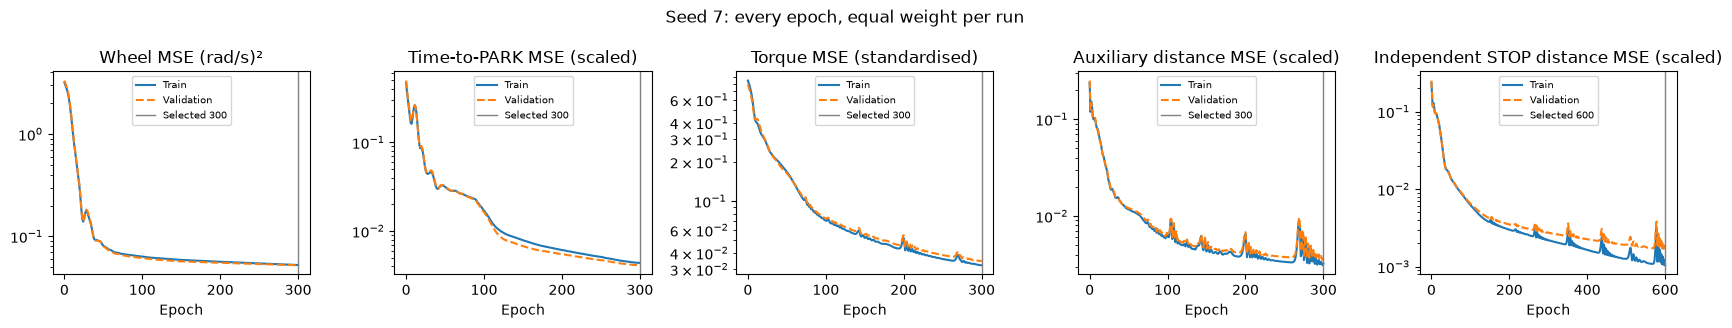

In [9]:
test_report.losses(7); plt.show()


#### Iteration 34: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


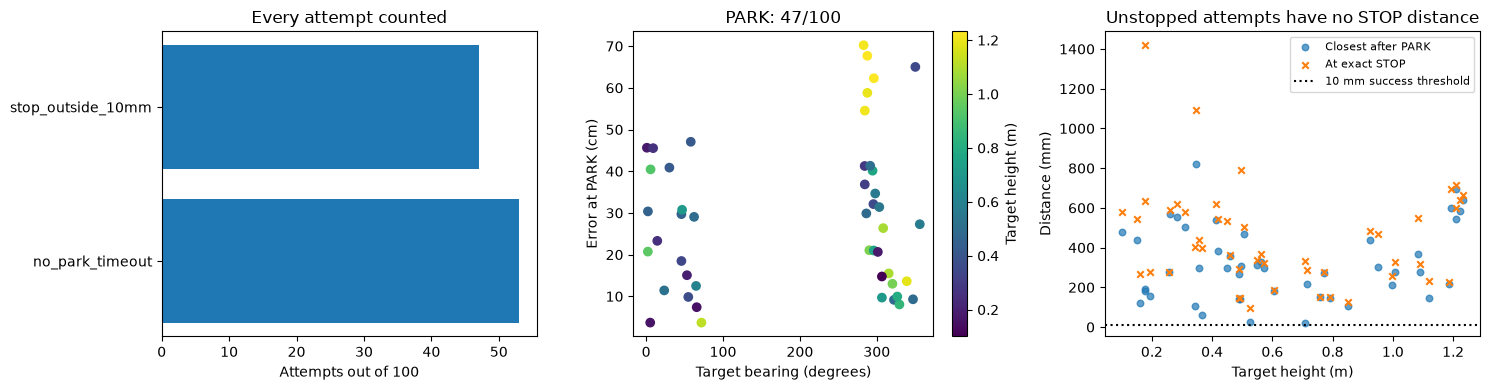

In [10]:
test_report.outcomes(7); plt.show()


#### Iteration 34: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


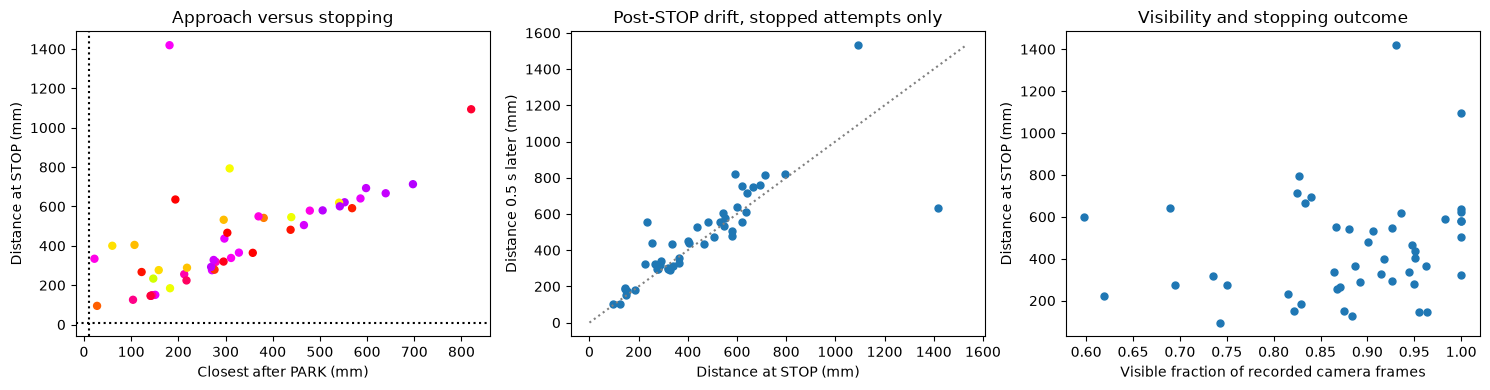

In [11]:
test_report.stopping(7); plt.show()


#### Iteration 34: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


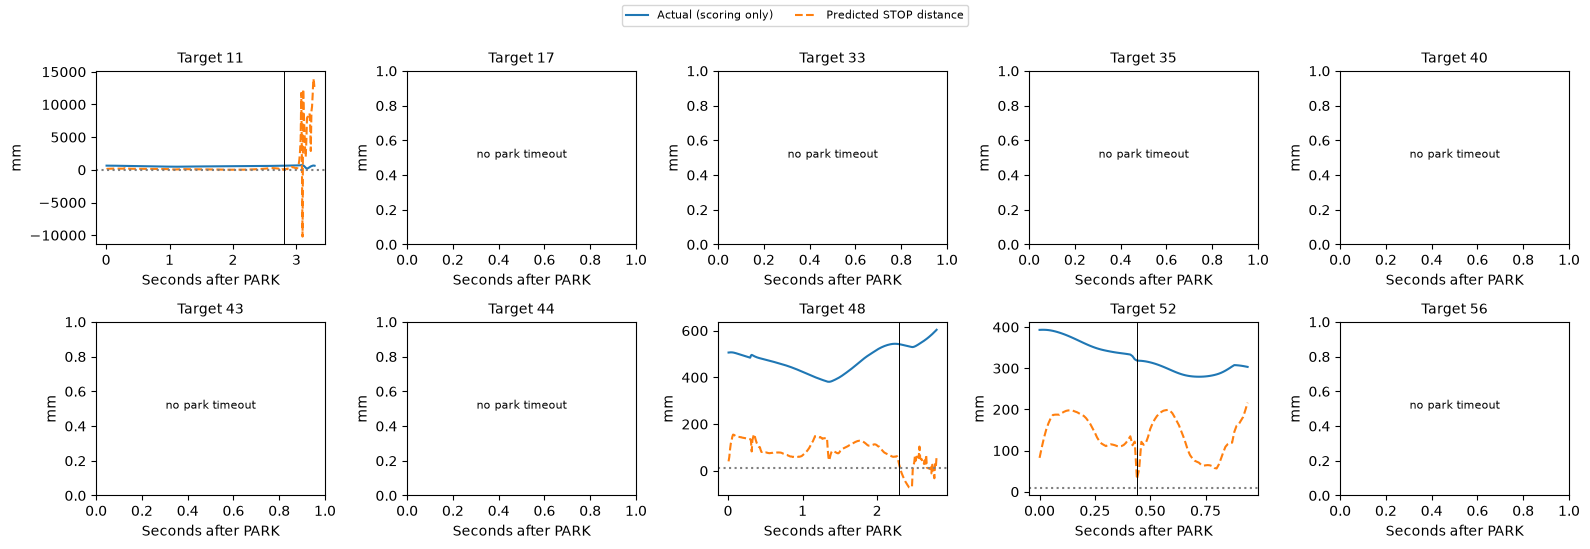

In [12]:
test_report.distances(7); plt.show()


#### Iteration 34: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [13]:
player_path = test_report.build_viewer(7)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 34: reading the result


In [14]:
display(Markdown(test_report.reading(7)))


Seed 7: 47/100 PARK, 47/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 0/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 27.3 cm among parked attempts; median distance at STOP was 400.4 mm among stopped attempts. 53 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

### Iteration 35: golden data, seed 1, results

Official test evaluation of the frozen seed-1 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [15]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(1).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.633,4.520,22.572,19.968,410.563,297.123,408.689,-1.874,1.379,False,9.185,0.987,0.986,1.042,0.178
17,no_stop_timeout,False,True,7.367,NaN,13.349,16.599,NaN,236.275,1128.734,NaN,3.943,True,19.052,0.682,194.926,1.095,1.028
33,stop_outside_10mm,False,True,5.633,9.069,8.248,13.004,425.545,96.087,998.686,573.141,1.960,False,15.939,0.906,259.736,1.504,0.422
35,no_stop_timeout,False,True,10.200,NaN,47.503,6.454,NaN,468.500,532.409,NaN,0.188,True,17.656,0.508,111.687,1.257,0.589
40,no_stop_timeout,False,True,6.633,NaN,17.528,20.830,NaN,267.001,406.636,NaN,1.549,True,19.739,0.779,205.751,1.041,0.328
43,no_stop_timeout,False,True,10.933,NaN,32.560,10.031,NaN,351.155,405.464,NaN,1.267,True,17.260,0.519,121.648,1.333,0.760
44,no_stop_timeout,False,True,10.233,NaN,54.503,8.700,NaN,613.677,923.565,NaN,3.504,True,20.755,0.655,140.983,1.684,0.533
48,stop_outside_10mm,False,True,4.300,6.740,14.262,-1.163,1014.756,153.960,1069.508,54.752,0.203,False,12.209,0.789,30.246,1.110,0.420
52,stop_outside_10mm,False,True,6.333,7.894,32.439,5.034,89.635,51.366,60.204,-29.431,1.268,False,13.475,0.937,315.534,1.244,1.090


#### Iteration 35: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


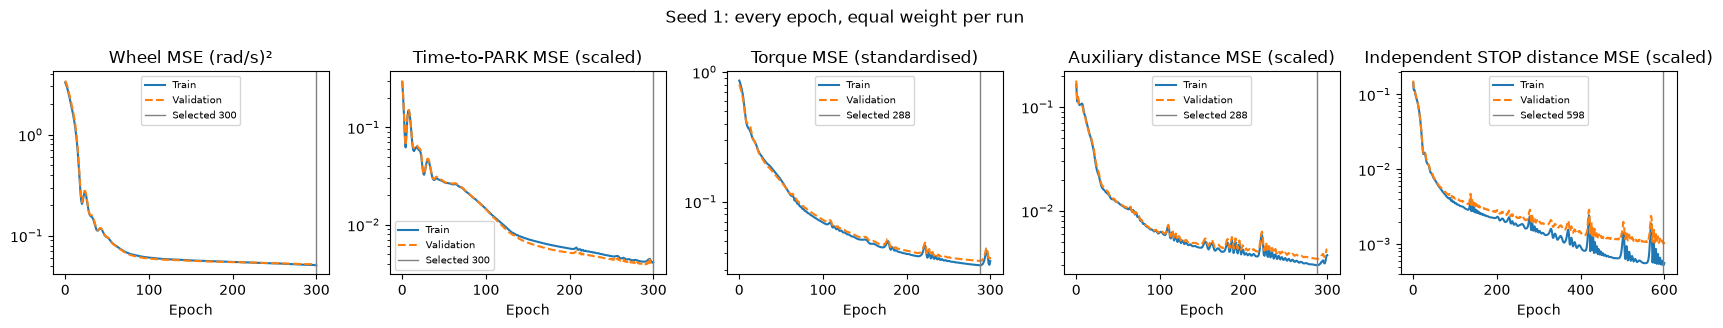

In [16]:
test_report.losses(1); plt.show()


#### Iteration 35: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


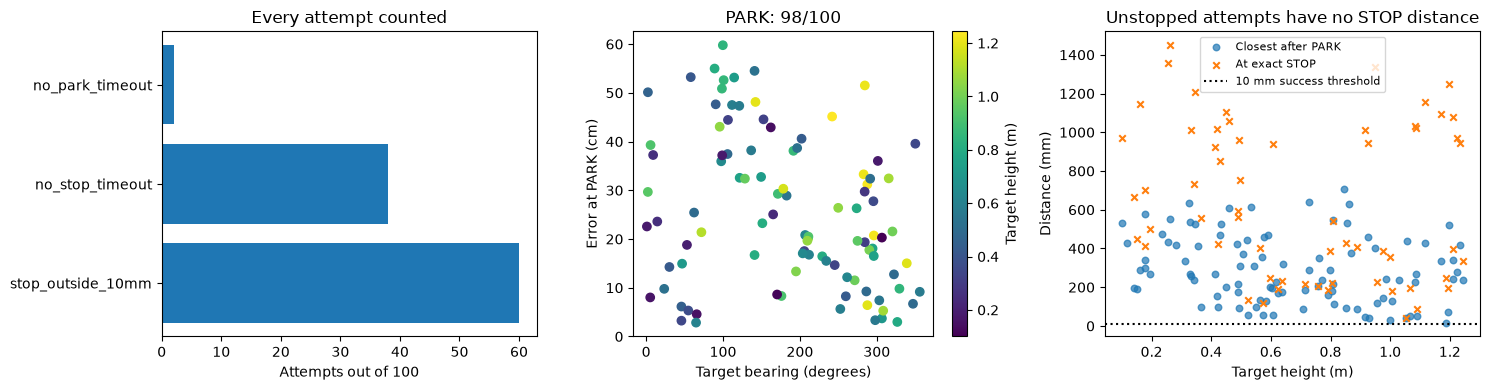

In [17]:
test_report.outcomes(1); plt.show()


#### Iteration 35: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


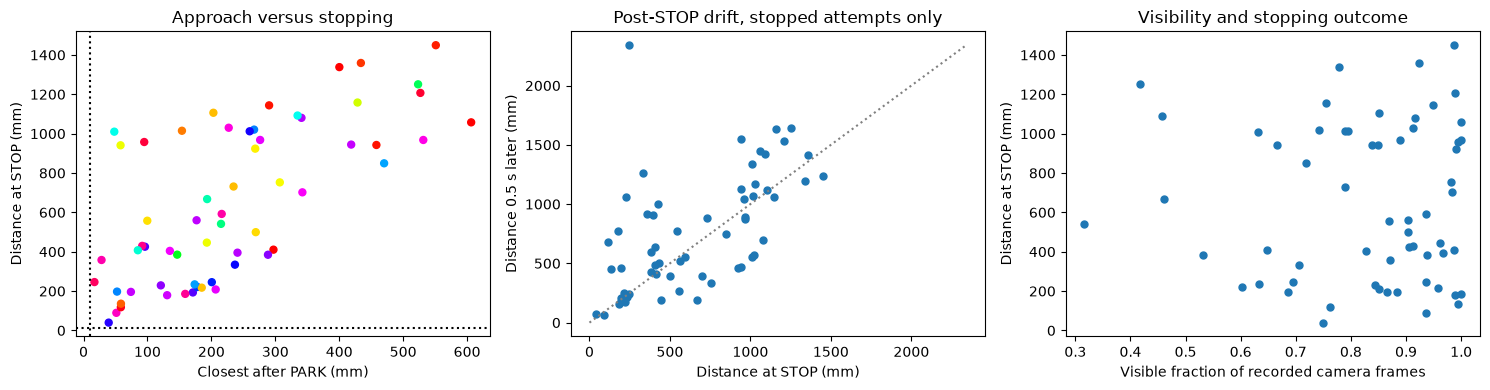

In [18]:
test_report.stopping(1); plt.show()


#### Iteration 35: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


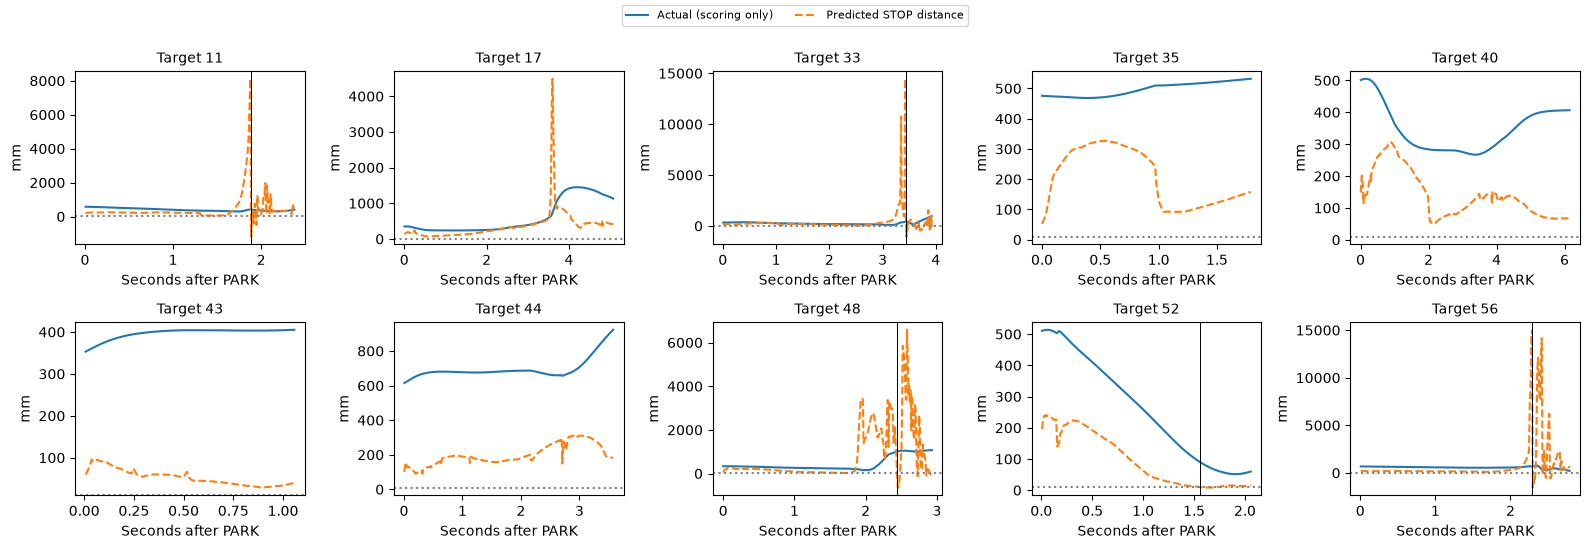

In [19]:
test_report.distances(1); plt.show()


#### Iteration 35: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [20]:
player_path = test_report.build_viewer(1)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 35: reading the result


In [21]:
display(Markdown(test_report.reading(1)))


Seed 1: 98/100 PARK, 60/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 0/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 22.1 cm among parked attempts; median distance at STOP was 558.8 mm among stopped attempts. 40 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

### Iteration 36: golden data, seed 2, results

Official test evaluation of the frozen seed-2 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [22]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(2).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,5.739,9.183,11.808,1070.808,112.180,570.852,-499.956,1.283,False,10.854,0.979,0.986,1.042,0.178
17,stop_outside_10mm,False,True,5.600,9.050,30.339,13.945,508.207,413.005,704.797,196.590,0.517,False,15.272,0.686,194.926,1.095,1.028
33,stop_outside_10mm,False,True,7.133,11.853,36.225,4.684,534.683,316.406,596.024,61.341,7.996,False,18.962,0.881,259.736,1.504,0.422
35,stop_outside_10mm,False,True,7.067,10.145,42.068,7.128,1626.615,417.772,1567.972,-58.643,1.031,False,16.718,0.625,111.687,1.257,0.589
40,stop_outside_10mm,False,True,5.400,7.739,15.442,11.870,271.810,63.110,342.378,70.567,0.300,False,13.837,0.629,205.751,1.041,0.328
43,no_stop_timeout,False,True,11.667,NaN,8.574,-21.285,NaN,185.418,185.326,NaN,0.139,True,17.397,0.569,121.648,1.333,0.760
44,stop_outside_10mm,False,True,9.267,12.695,42.746,-19.657,1168.125,462.752,1459.010,290.885,0.282,False,20.155,0.808,140.983,1.684,0.533
48,stop_outside_10mm,False,True,4.900,5.665,14.703,-16.214,273.143,266.617,319.793,46.650,1.525,False,10.342,0.946,30.246,1.110,0.420
52,stop_outside_10mm,False,True,5.967,9.637,25.878,5.426,1497.788,289.142,1712.692,214.904,1.886,False,15.829,0.649,315.534,1.244,1.090


#### Iteration 36: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


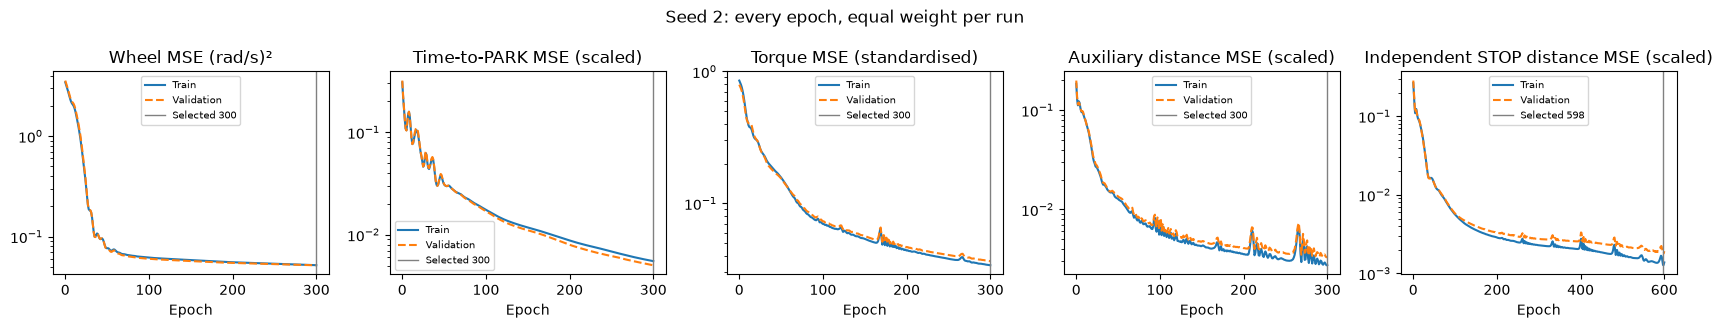

In [23]:
test_report.losses(2); plt.show()


#### Iteration 36: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


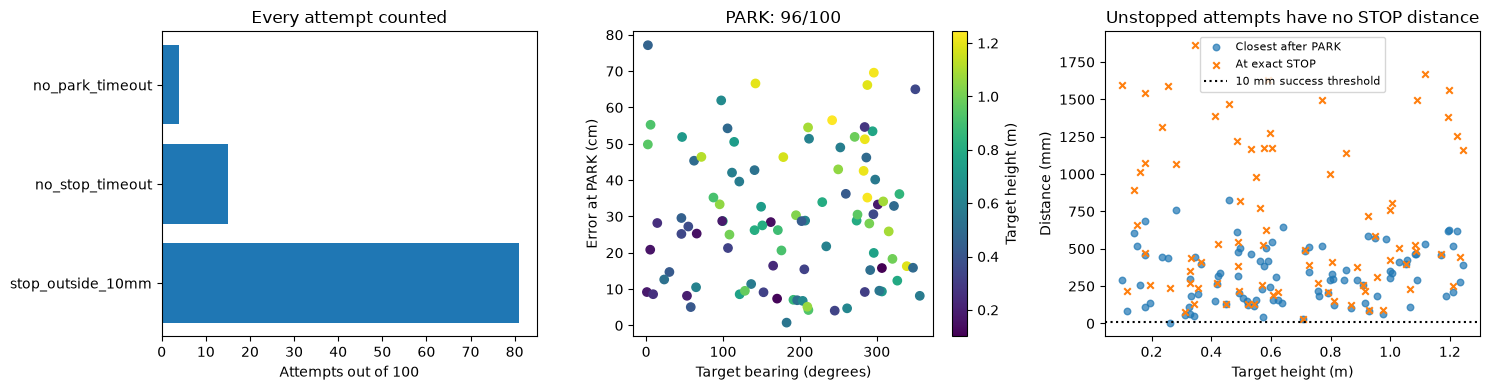

In [24]:
test_report.outcomes(2); plt.show()


#### Iteration 36: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


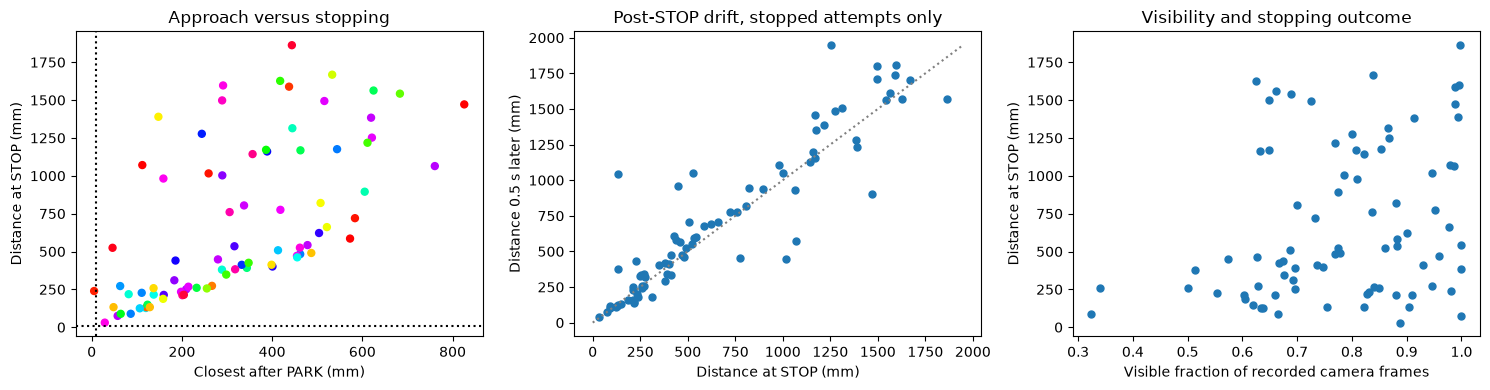

In [25]:
test_report.stopping(2); plt.show()


#### Iteration 36: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


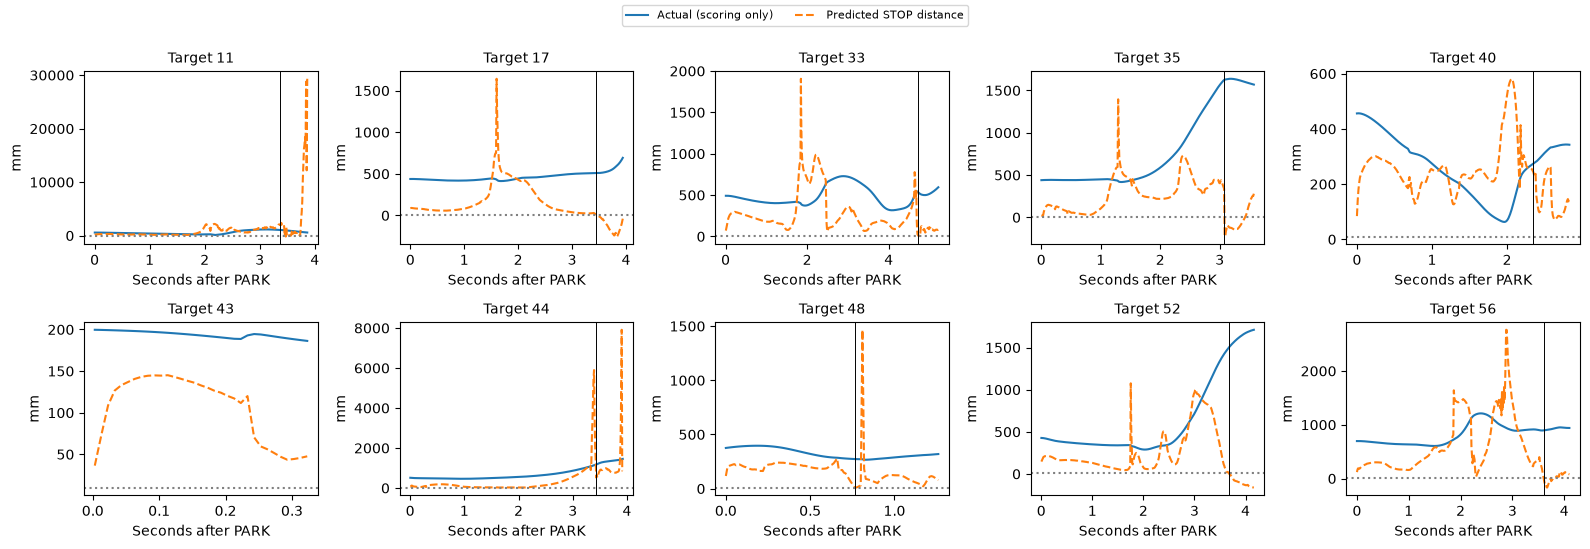

In [26]:
test_report.distances(2); plt.show()


#### Iteration 36: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [27]:
player_path = test_report.build_viewer(2)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 36: reading the result


In [28]:
display(Markdown(test_report.reading(2)))


Seed 2: 96/100 PARK, 81/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 1/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 28.6 cm among parked attempts; median distance at STOP was 490.3 mm among stopped attempts. 19 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

## Interpretation and next work

This completes the frozen baseline evaluation. Differences between seeds measure the variation from training on the same data. Future planned changes should be selected using training/validation, then evaluated on these same fixed test IDs. Test outcomes do not select a checkpoint or change a deadline.

The historical `driving_v2_sensors.ipynb` remains unchanged at 361 cells. Validation smoke checks are not official MLflow runs; iterations 34 to 36 contain the full tests and original training histories.
